In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math
import os

from sklearn.datasets import load_iris
from sklearn.decomposition import PCA
from sklearn.manifold import Isomap
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold

In [26]:
# Checking Question 1
X = np.array([
    [-2, -1],
    [-1, 0],
    [0, 1],
    [1, 2],
    [2, 3]
], dtype=float)

mu = X.mean(axis=0)
Xc = X - mu

C = np.cov(Xc, rowvar=False)
vals, vecs = np.linalg.eigh(C) # eigen decomposition
u = vecs[:, -1]

def recon_error(p):
    p = np.asarray(p, dtype=float)
    pc = p - mu
    t = pc @ u
    recon = t * u
    residual = pc - recon
    return np.linalg.norm(residual)

print(mu, vals, u)
print(recon_error([3, 3]), recon_error([3, 4]))

[0. 1.] [0. 5.] [0.70710678 0.70710678]
0.7071067811865476 6.280369834735101e-16


(150, 4) ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)'] ['setosa' 'versicolor' 'virginica']


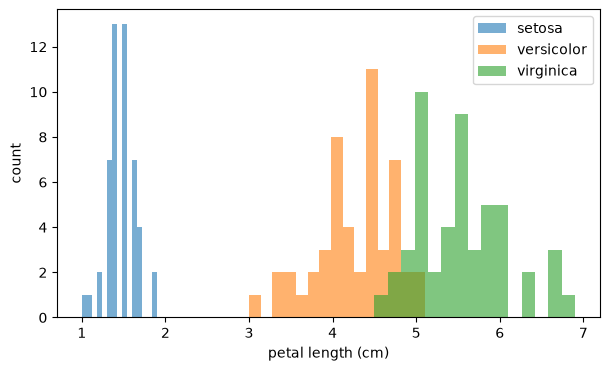

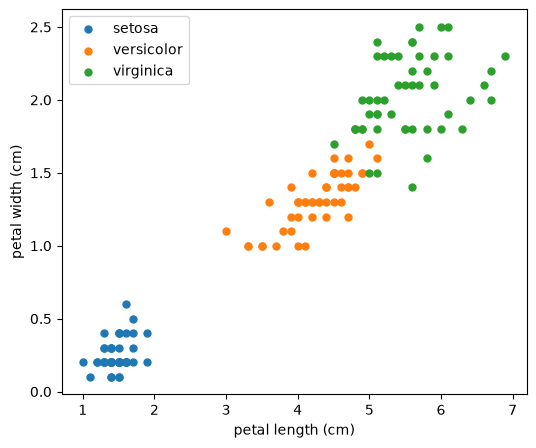

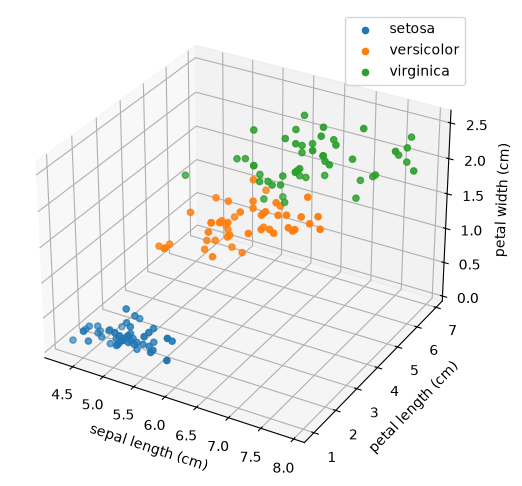

In [27]:
# Question 2
iris = load_iris()
X, y = iris.data, iris.target
names, species = iris.feature_names, iris.target_names
colors = ["tab:blue", "tab:orange", "tab:green"]
print(X.shape, names, species)

# One feature (petal length)
f = 2
plt.figure(figsize=(7, 4))
for k in range(3):
    plt.hist(X[y == k, f], bins=15, alpha=0.6, color=colors[k], label=species[k])
plt.xlabel(names[f])
plt.ylabel("count")
plt.legend()
plt.savefig(os.path.join("media", "iris-1d-petal-length.png"), dpi=150, bbox_inches="tight")
plt.show()

# Two features (petal length, petal width):
i, j = 2, 3
plt.figure(figsize=(6, 5))
for k in range(3):
    plt.scatter(X[y == k, i], X[y == k, j], c=colors[k], label=species[k], s=25)
plt.xlabel(names[i])
plt.ylabel(names[j])
plt.legend()
plt.savefig(os.path.join("media", "iris-2d-petal.png"), dpi=150, bbox_inches="tight")
plt.show()

# Three features (sepal length, petal length, petal width):
a, b, c = 0, 2, 3
fig = plt.figure(figsize=(7, 6))
ax = fig.add_subplot(projection="3d")
for k in range(3):
    ax.scatter(X[y == k, a], X[y == k, b], X[y == k, c], c=colors[k], label=species[k], s=20)
ax.set_xlabel(names[a])
ax.set_ylabel(names[b])
ax.set_zlabel(names[c])
ax.legend()
plt.savefig(os.path.join("media", "iris-3d-sepal-petal.png"), dpi=150, bbox_inches="tight")
plt.show()


     sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
PC1             0.3614           -0.0845             0.8567            0.3583
PC2             0.6566            0.7302            -0.1734           -0.0755
PC3            -0.5820            0.5979             0.0762            0.5458
[0.9246 0.0531 0.0171] [0.9246 0.9777 0.9948]


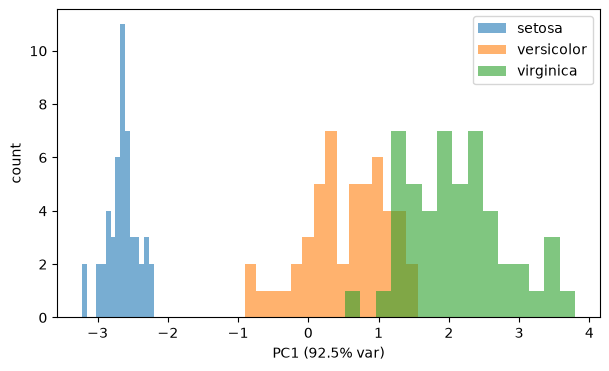

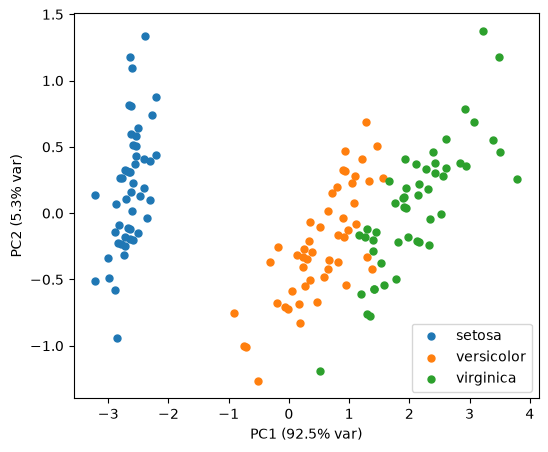

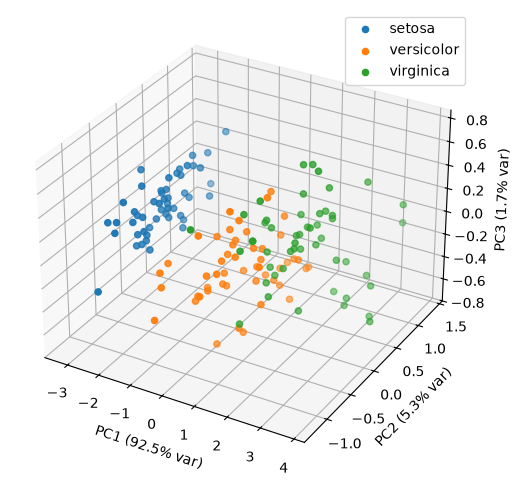

In [28]:
# Question 3
pca = PCA(n_components=3).fit(X)
Z = pca.transform(X)
ratio = pca.explained_variance_ratio_

axes = pd.DataFrame(pca.components_, columns=names, index=["PC1", "PC2", "PC3"])
print(axes.round(4))
print(ratio.round(4), ratio.cumsum().round(4))

label = [f"PC{k + 1} ({ratio[k]:.1%} var)" for k in range(3)]

plt.figure(figsize=(7, 4))
for k in range(3):
    plt.hist(Z[y == k, 0], bins=15, alpha=0.6, color=colors[k], label=species[k])
plt.xlabel(label[0])
plt.ylabel("count")
plt.legend()
plt.savefig(os.path.join("media", "pca-1d.png"), dpi=150, bbox_inches="tight")
plt.show()

plt.figure(figsize=(6, 5))
for k in range(3):
    plt.scatter(Z[y == k, 0], Z[y == k, 1], c=colors[k], label=species[k], s=25)
plt.xlabel(label[0])
plt.ylabel(label[1])
plt.legend()
plt.savefig(os.path.join("media", "pca-2d.png"), dpi=150, bbox_inches="tight")
plt.show()

fig = plt.figure(figsize=(7, 6))
ax = fig.add_subplot(projection="3d")
for k in range(3):
    ax.scatter(Z[y == k, 0], Z[y == k, 1], Z[y == k, 2], c=colors[k], label=species[k], s=20)
ax.set_xlabel(label[0])
ax.set_ylabel(label[1])
ax.set_zlabel(label[2])
ax.legend()
plt.savefig(os.path.join("media", "pca-3d.png"), dpi=150, bbox_inches="tight")
plt.show() 

In [29]:
# Question 4
pca_full = PCA().fit(X)
ratio_full = pca_full.explained_variance_ratio_
cumulative = ratio_full.cumsum()
print(ratio_full.round(4))
print(cumulative.round(4))

print("2D representation explains:", f"{cumulative[1]:.2%}")
print("PCs needed for 50%:", int(np.searchsorted(cumulative, 0.5) + 1))

Xc = X - X.mean(axis=0)
frob_sq = (Xc ** 2).sum()
total_var = frob_sq / (len(X) - 1)
eigen_sum = pca_full.explained_variance_.sum()
print(total_var, eigen_sum, np.allclose(total_var, eigen_sum))

[0.9246 0.0531 0.0171 0.0052]
[0.9246 0.9777 0.9948 1.    ]
2D representation explains: 97.77%
PCs needed for 50%: 1
4.572957046979866 4.572957046979804 True


(150, 2) 0.436434791531871


/home/lukeypookster/.venvs/school/lib/python3.14/site-packages/sklearn/manifold/_isomap.py:386: UserWarning: The number of connected components of the neighbors graph is 2 > 1. Completing the graph to fit Isomap might be slow. Increase the number of neighbors to avoid this issue.
  self._fit_transform(X)
/home/lukeypookster/.venvs/school/lib/python3.14/site-packages/scipy/sparse/_index.py:174: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil and dok are more efficient.
  self._set_intXint(row, col, x.flat[0])


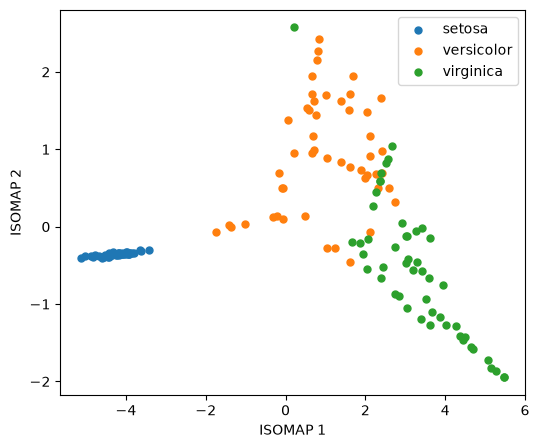

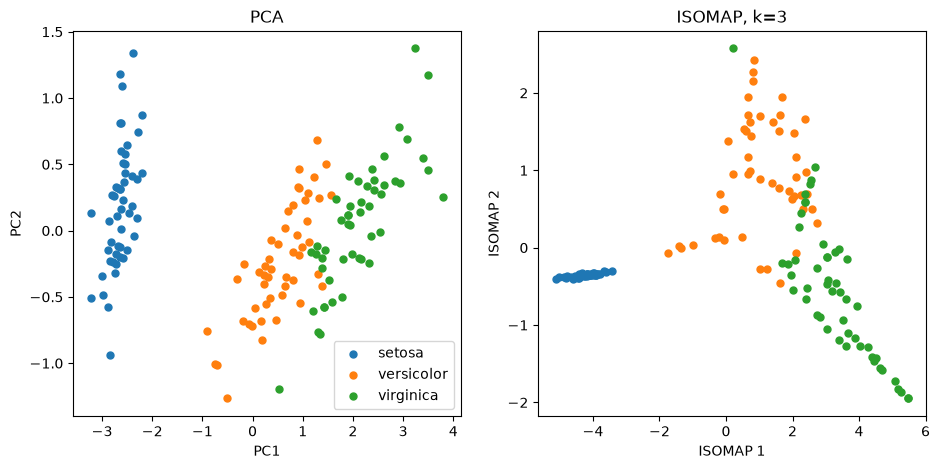

In [30]:
# Question 5
iso = Isomap(n_neighbors=3, n_components=2)
E = iso.fit_transform(X)
print(E.shape, iso.reconstruction_error())

plt.figure(figsize=(6, 5))
for k in range(3):
    plt.scatter(E[y == k, 0], E[y == k, 1], c=colors[k], label=species[k], s=25)
plt.xlabel("ISOMAP 1")
plt.ylabel("ISOMAP 2")
plt.legend()
plt.savefig(os.path.join("media", "isomap-2d.png"), dpi=150, bbox_inches="tight")
plt.show()

Z2 = PCA(n_components=2).fit_transform(X)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 5))
for k in range(3):
    ax1.scatter(Z2[y == k, 0], Z2[y == k, 1], c=colors[k], label=species[k], s=25)
    ax2.scatter(E[y == k, 0], E[y == k, 1], c=colors[k], label=species[k], s=25)
ax1.set_title("PCA")
ax1.set_xlabel("PC1")
ax1.set_ylabel("PC2")
ax2.set_title("ISOMAP, k=3")
ax2.set_xlabel("ISOMAP 1")
ax2.set_ylabel("ISOMAP 2")
ax1.legend()
plt.savefig(os.path.join("media", "pca-vs-isomap.png"), dpi=150, bbox_inches="tight")
plt.show()

In [31]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
knn = KNeighborsClassifier(n_neighbors=5)

representations = {
    "raw 4D": X,
    "PCA 2D": Z[:, :2],
    "ISOMAP 2D": E,
}

for name in representations:
    data = representations[name]
    scores = cross_val_score(knn, data, y, cv=cv)
    mean = scores.mean()
    std = scores.std()
    print(name, round(mean, 4), "+/-", round(std, 4))

raw 4D 0.9533 +/- 0.0163
PCA 2D 0.96 +/- 0.0389
ISOMAP 2D 0.9267 +/- 0.0249
